# Benchmarking Comparison

- Creator: Sebastian Birk (sb75@sanger.ac.uk)
- Date of Creation: 26.01.2025
- Date of Last Modification: 27.01.2025 (by Sebastian Birk; sb75@sanger.ac.uk)

- Run this notebook in the nichejepa conda environment, installable from ```../../envs/nichejepa.yaml```.

## 1. Setup

### 1.1 Load Libraries 

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../../utils")

In [5]:
import os

import anndata as ad
import pandas as pd
import scanpy as sc
from collections import OrderedDict
from matplotlib.lines import Line2D

from analysis_utils import *
from benchmarking_utils import max_overlap_plot

### 1.2 Configure Paths

In [6]:
st_data_folder_path = '/lustre/scratch126/cellgen/team361/DATASETS'
st_data_silver_folder_path = f'{st_data_folder_path}/silver'
artifacts_folder_path = '/lustre/scratch126/cellgen/team361/sb75/nichejepa-reproducibility/artifacts'
benchmarking_artifacts_folder_path = f'{artifacts_folder_path}/benchmarking'

### 1.3 Define Config

### 1.4 Run Notebook Setup

In [7]:
# Improve reproducibility of UMAP and Leiden
os.environ['NUMBA_CPU_NAME'] = 'generic'

In [8]:
sc.settings.figdir = f'{benchmarking_artifacts_folder_path}/figures'

sc.settings.set_figure_params(
    dpi=300,
    dpi_save=300,
    figsize=(3, 2),
    facecolor='white',
    fontsize=7
)

In [9]:
os.makedirs(f'{benchmarking_artifacts_folder_path}/figures', exist_ok=True)
os.makedirs(f'{benchmarking_artifacts_folder_path}/results', exist_ok=True)

## 2. Metric Comparisons

In [12]:
cellplm_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_cellplm_metric_scores.csv')
cellplm_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_cellplm_metric_scores.csv')
cellplm_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_cellplm_metric_scores.csv')
novae_49_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/xhs49-1b_1p_novae_metric_scores.csv')
novae_59_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chl59-8b_1p_novae_metric_scores.csv')
novae_78_df = pd.read_csv(f'{benchmarking_artifacts_folder_path}/results/chr78-11b_1p_novae_metric_scores.csv')

cellplm_49_df['dataset'] = 'Xenium Human Melanoma'
cellplm_59_df['dataset'] = 'NanoString CosMx Human NSCLC'
cellplm_78_df['dataset'] = 'ISS Cartana Human Reproductive Tract'
novae_49_df['dataset'] = 'Xenium Human Melanoma'
novae_59_df['dataset'] = 'NanoString CosMx Human NSCLC'
novae_78_df['dataset'] = 'ISS Cartana Human Reproductive Tract'

cellplm_49_df['method'] = 'CellPLM'
cellplm_59_df['method'] = 'CellPLM'
cellplm_78_df['method'] = 'CellPLM'
novae_49_df['method'] = 'Novae'
novae_59_df['method'] = 'Novae'
novae_78_df['method'] = 'Novae'

df = pd.concat([cellplm_49_df, cellplm_59_df, cellplm_78_df, novae_49_df, novae_59_df, novae_78_df], ignore_index=True)

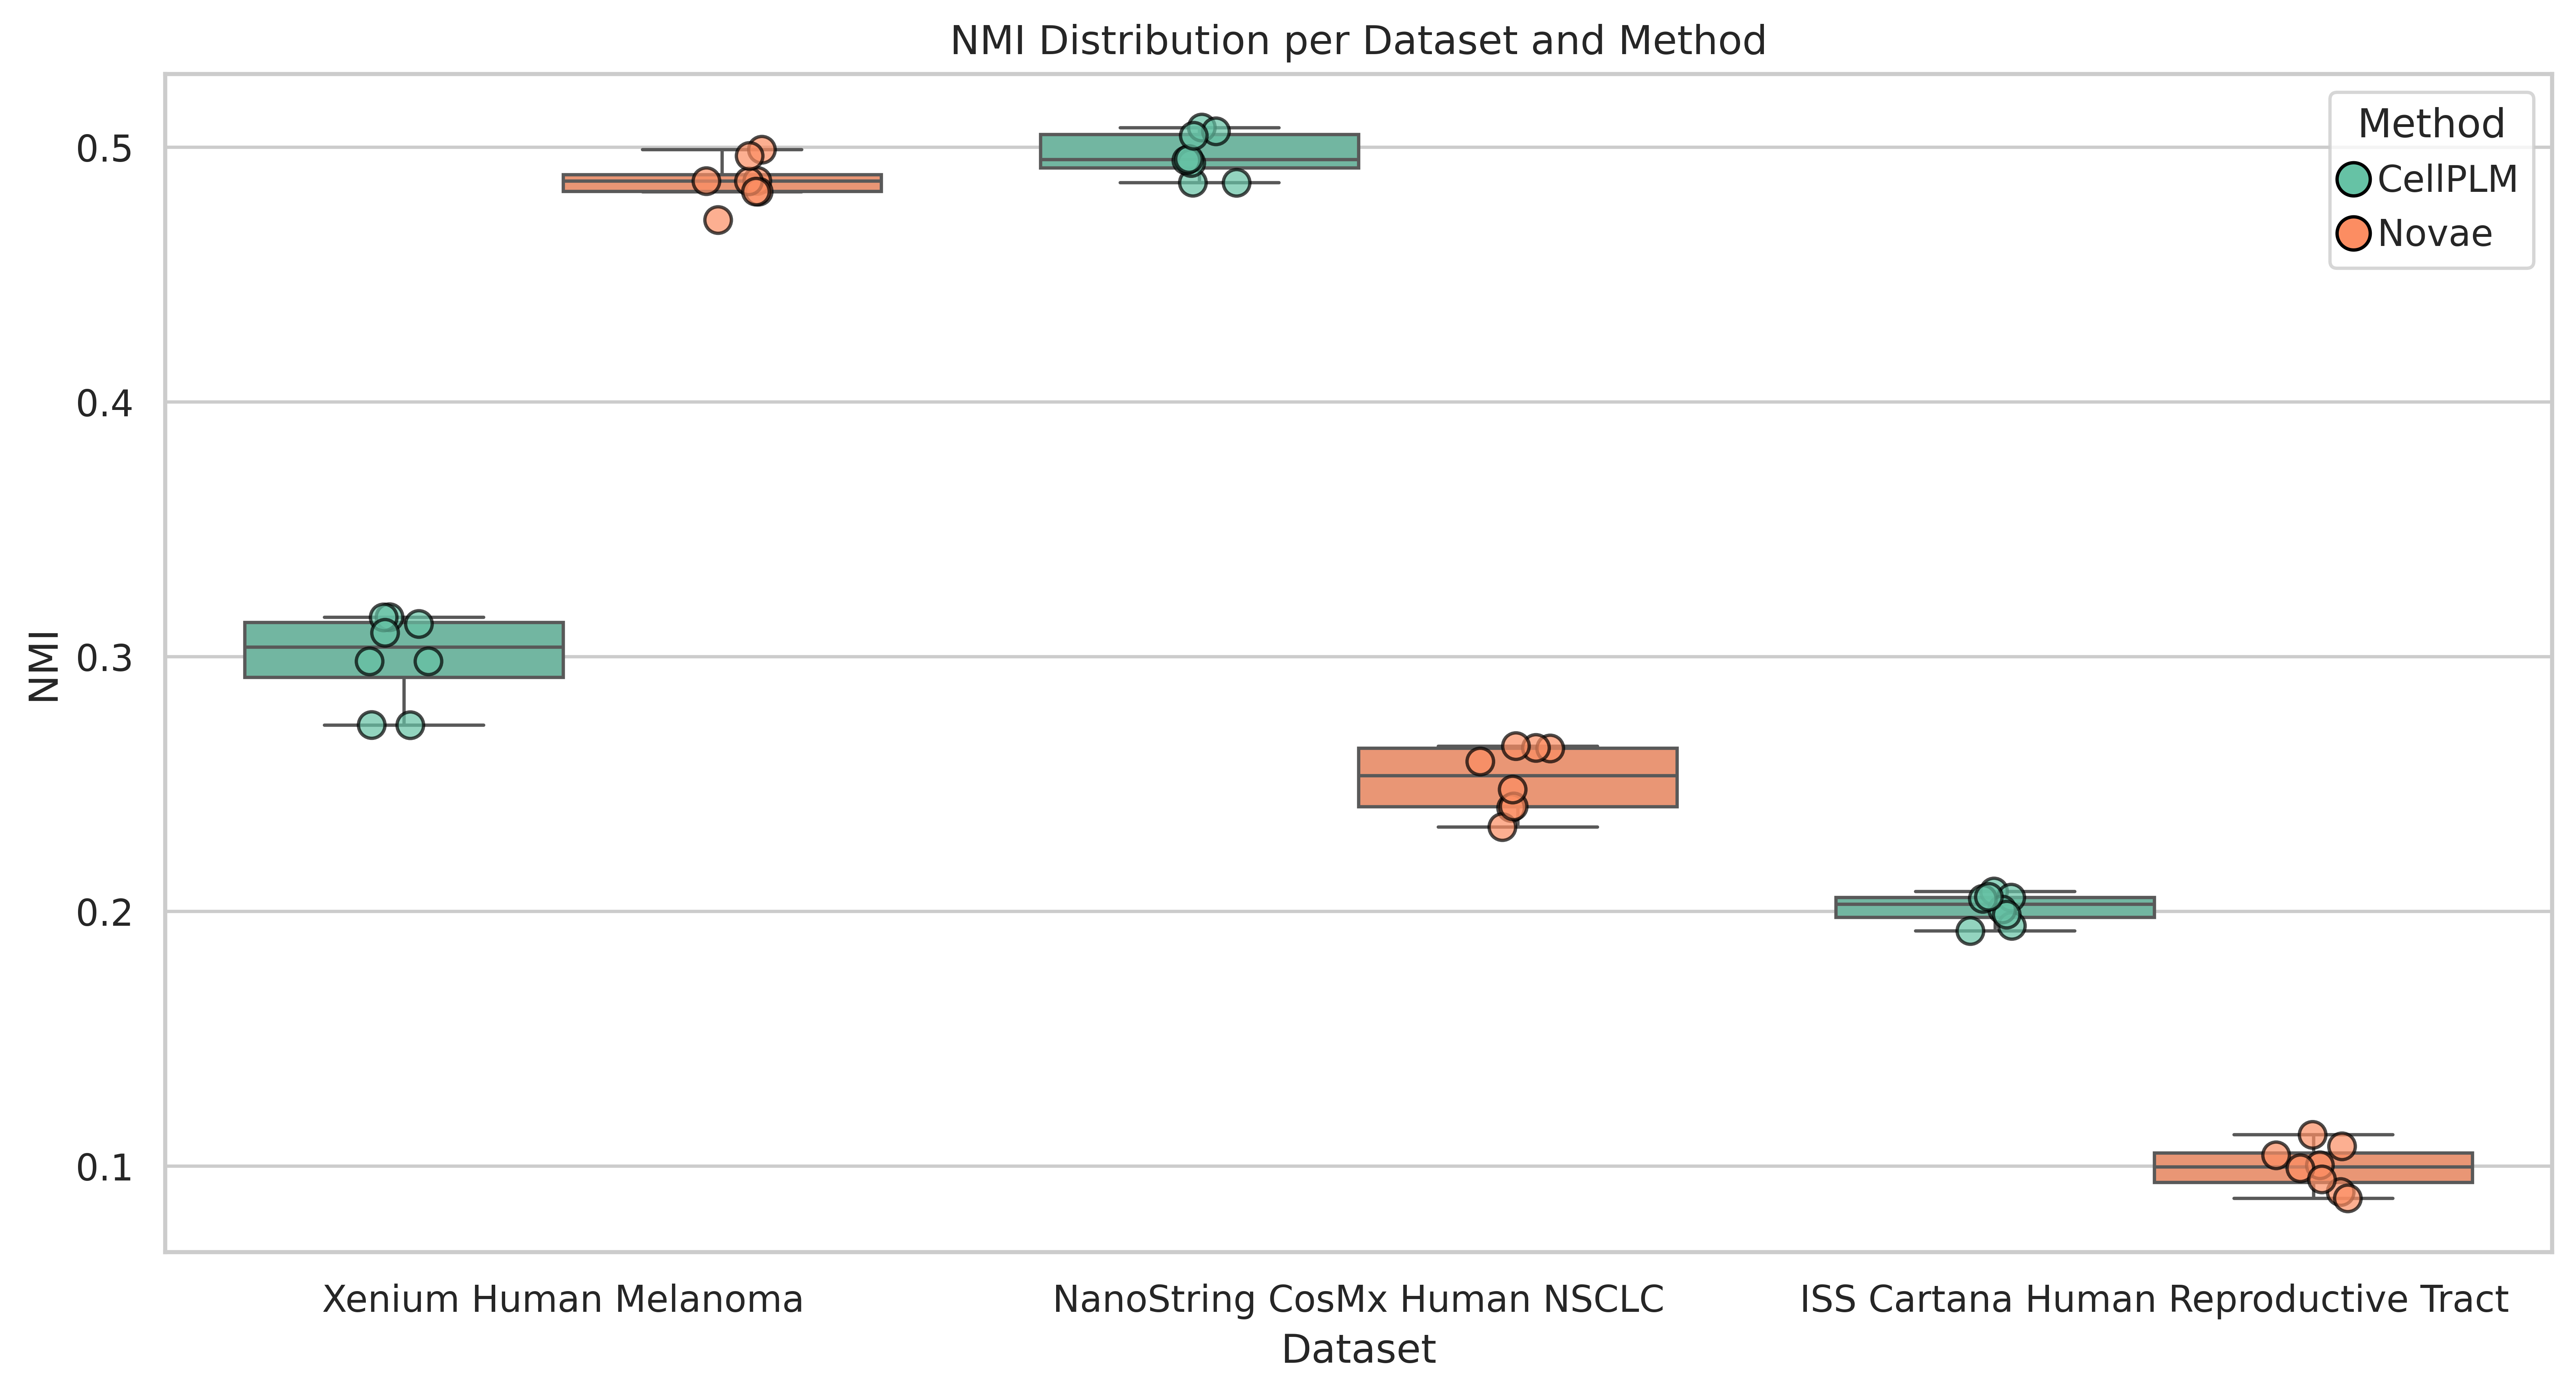

In [13]:
plt.rcParams.update({
    'font.size': 24,
    'axes.titlesize': 24,
    'axes.labelsize': 24,
    'xtick.labelsize': 24,
    'ytick.labelsize': 24,
    'legend.fontsize': 24,
    'legend.title_fontsize': 24
})

# Set the aesthetic style of the plots
sns.set(style="whitegrid")

# Initialize the matplotlib figure with a specific size
plt.figure(figsize=(11, 6))  # Increased figure size for better visibility

# Define a color palette (optional: customize as needed)
palette = "Set2"  # You can choose other palettes like "Set1", "Set3", etc.

# Create the boxplot
ax = sns.boxplot(
    x='dataset',
    y='NMI',
    hue='method',
    data=df,
    palette=palette,
    dodge=True,
    showfliers=False  # Hide outliers for a cleaner look
)

# Overlay the scatter points with the same hue and palette
sns.stripplot(
    x='dataset',
    y='NMI',
    hue='method',
    data=df,
    dodge=True,
    jitter=True,
    alpha=0.7,
    size=8,  # Increased dot size
    marker='o',
    edgecolor='black',  # Changed to black edges
    linewidth=1,        # Add linewidth for better edge visibility
    palette=palette,    # Ensure the palette matches the boxplot
    ax=ax
)

# Handle the legend to avoid duplicates
handles, labels = ax.get_legend_handles_labels()
by_label = OrderedDict(zip(labels, handles))  # Remove duplicate labels

# Remove the existing legend
ax.legend_.remove()

# Create custom legend handles with desired properties
unique_methods = list(by_label.keys())
palette_colors = sns.color_palette(palette, n_colors=len(unique_methods))

custom_handles = [
    Line2D([0], [0], marker='o', color='w', label=method,
           markerfacecolor=palette_colors[i],
           markeredgecolor='black', markersize=10)
    for i, method in enumerate(unique_methods)
]

# Add the custom legend
ax.legend(handles=custom_handles, title='Method')

# Add titles and labels with appropriate font sizes
plt.title('NMI Distribution per Dataset and Method')
plt.xlabel('Dataset')
plt.ylabel('NMI')

# Adjust layout for better fit and prevent clipping of labels
plt.tight_layout()

# Display the plot
plt.savefig(f'{benchmarking_artifacts_folder_path}/figures/benchmarking_comparison.svg', dpi=300)
plt.show()